## Working datasets

In [7]:
from datasets import load_dataset

dataset = load_dataset("dair-ai/emotion")

In [8]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [9]:
df = dataset["train"].to_pandas()
label_names = dataset["train"].features["label"].names
# label_names
df['label_text'] = df['label'].apply(lambda x: label_names[x])
df


,text,label,label_text
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger
...,...,...,...
15995,i just had a very brief time in the beanbag an...,0,sadness
15996,i am now turning and i feel pathetic that i am...,0,sadness
15997,i feel strong and good overall,1,joy
15998,i feel like this was such a rude comment and i...,3,anger


## Analysis of data using Matplotlib

In [10]:
import matplotlib.pyplot as plt

label_counts = df['label_text'].value_counts(ascending=True)
label_counts

label_text
surprise     572
love        1304
fear        1937
anger       2159
sadness     4666
joy         5362
Name: count, dtype: int64

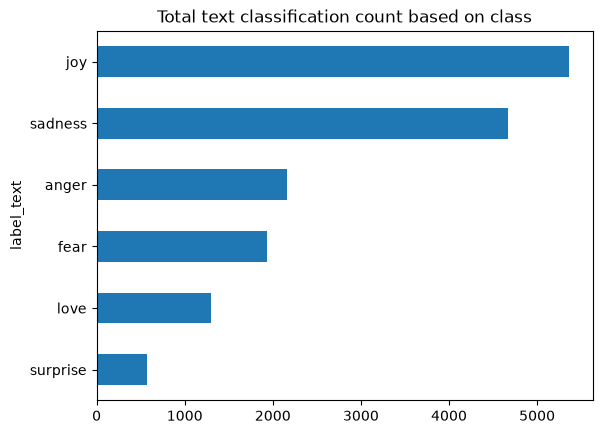

In [11]:
label_counts.plot.barh()
plt.title('Total text classification count based on class')
plt.show()

## Tokenization of data from the raw String

In [12]:
from transformers import AutoTokenizer

model_checkpoint = 'bert-base-uncased'

In [13]:
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

text = "I love ML and ML is the future"
encoded_txt = tokenizer(text)

print(f"Original text: {text}")
print(f"Encoded text: {encoded_txt}")

Original text: I love ML and ML is the future
Encoded text: {'input_ids': [101, 1045, 2293, 19875, 1998, 19875, 2003, 1996, 2925, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


## Split the data as 

1) Training data
2) Test Data
3) Validation Data

In [14]:
from sklearn.model_selection import train_test_split
#70% of data = Train data, 20% of data = Test Data, 10% of data = Validation data

train, test = train_test_split(df,test_size = 0.3,stratify = df['label_text'])
test,validation = train_test_split(test,test_size = 1/3,stratify = test['label'])
train.shape, test.shape, validation.shape

((11200, 3), (3200, 3), (1600, 3))

In [15]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [16]:
from datasets import Dataset, DatasetDict

dataset = DatasetDict({
    'train': Dataset.from_pandas(train, preserve_index=False),
    'test': Dataset.from_pandas(test, preserve_index=False),
    'validation': Dataset.from_pandas(validation, preserve_index=False)
})

dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 11200
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3200
    })
    validation: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1600
    })
})

In [17]:
dataset["train"][0],dataset["test"][0],dataset["validation"][0]

({'text': 'im feeling lucky button after that you will go to the landing page where you will found the alternative google search engine homepage with colors theme depend on the keywords below',
  'label': 1,
  'label_text': 'joy'},
 {'text': 'i get a good feeling i get a feeling that i never never had before i thought it was so clever sticking a needle in my arm to that song',
  'label': 1,
  'label_text': 'joy'},
 {'text': 'i would have smiled except i was starting to feel like any more uptight comments and my jaw would fall right out of my head',
  'label': 4,
  'label_text': 'fear'})

## Tokenize All the text in the Dataset using Map function of HuggingFace

In [18]:
def tokenize(batch):
    return tokenizer(batch['text'], padding=True, truncation=True)

tokenize(dataset['train'][:3])
# tokenized_datasets = dataset.map(tokenize, batched=True, batch_size=None)

{'input_ids': [[101, 10047, 3110, 5341, 6462, 2044, 2008, 2017, 2097, 2175, 2000, 1996, 4899, 3931, 2073, 2017, 2097, 2179, 1996, 4522, 8224, 3945, 3194, 2188, 13704, 2007, 6087, 4323, 12530, 2006, 1996, 3145, 22104, 2917, 102, 0, 0, 0, 0, 0, 0, 0, 0], [101, 1045, 2079, 2025, 4737, 2055, 2296, 16371, 6651, 1997, 2026, 2154, 1998, 2049, 8312, 2000, 2500, 2625, 2210, 2477, 2000, 4737, 2055, 1998, 2008, 3084, 2033, 2514, 2625, 11265, 10976, 4588, 3452, 1998, 2625, 3497, 2000, 9495, 27756, 4178, 2004, 2092, 102], [101, 1045, 2514, 2023, 2003, 2074, 2178, 12266, 20228, 6977, 2209, 2011, 6683, 27528, 2000, 3535, 2000, 4468, 1037, 6012, 2012, 1996, 2398, 1997, 9889, 4599, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [19]:
encoded = dataset.map(tokenize, batched=True, batch_size=None)

Map: 100%|██████████| 1600/1600 [00:00<00:00, 31120.93 examples/s]


In [20]:
encoded

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 11200
    })
    test: Dataset({
        features: ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3200
    })
    validation: Dataset({
        features: ['text', 'label', 'label_text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1600
    })
})

## Working with Models

In [21]:
from transformers import AutoModel
model = AutoModel.from_pretrained(model_checkpoint)
# model.config.id2label
model.config.id2label, model.config.label2id

label2id = {label: i for i, label in enumerate(label_names)}
id2label = {i: label for i, label in enumerate(label_names)}

label2id, id2label

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 586.74it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


({'sadness': 0, 'joy': 1, 'love': 2, 'anger': 3, 'fear': 4, 'surprise': 5},
 {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'})

In [22]:
model

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

In [23]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, AutoConfig
import torch


if torch.has_mps:
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
    
config = AutoConfig.from_pretrained(model_checkpoint, label2id=label2id, id2label=id2label)
model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, config=config).to(device)

C:\Users\Nutan Gupta\AppData\Local\Temp\ipykernel_11408\3954972081.py:5: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  if torch.has_mps:


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 429.54it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoin

In [24]:
model.config

BertConfig {
  "add_cross_attention": false,
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "id2label": {
    "0": "sadness",
    "1": "joy",
    "2": "love",
    "3": "anger",
    "4": "fear",
    "5": "surprise"
  },
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "label2id": {
    "anger": 3,
    "fear": 4,
    "joy": 1,
    "love": 2,
    "sadness": 0,
    "surprise": 5
  },
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "tie_word_embeddings": true,
  "transformers_version": "5.18.0",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size":

## Model Training

1. Training Argument 
2. Build the trainer along with the argument
3. Start the training itself.

Evalute the model = Compute metrics

In [25]:
%pip install --upgrade "accelerate>=1.1.0"

Note: you may need to restart the kernel to use updated packages.


c:\Users\Nutan Gupta\Desktop\Gen-Ai\training-model\Training-model\.venv\Scripts\python.exe: No module named pip


In [26]:
from transformers import TrainingArguments

batch_size = 64
training_dir = "bert_base_uncased_trained_model"

training_args = TrainingArguments(
                                  output_dir=training_dir,
                                  # overwrite_output_dir=True,
                                  num_train_epochs= 2,
                                  learning_rate= 2e-5,
                                  per_device_eval_batch_size=batch_size,
                                  per_device_train_batch_size=batch_size,
                                  weight_decay=0.01,
                                  eval_strategy='epoch',
                                  disable_tqdm=False)

### Build the Compute Metrics

In [27]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)

    f1 = f1_score(labels,preds , average = 'weighted')    
    acc = accuracy_score(labels, preds)
    return {'accuracy': acc, 'F1 score': f1}

### Building a Trainer

In [31]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    compute_metrics=compute_metrics,
    train_dataset= encoded['train'],
    eval_dataset=encoded['validation'],
    processing_class=tokenizer,
)

trainer

In [33]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Trainer device:", trainer.args.device)
print("Model device:", next(trainer.model.parameters()).device)
print("Batch size:", trainer.args.per_device_train_batch_size)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu
CUDA available: False
Trainer device: cpu
Model device: cpu
Batch size: 64


In [32]:
trainer.train()


c:\Users\Nutan Gupta\Desktop\Gen-Ai\training-model\Training-model\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 